In [3]:
# imports
import simpy
import numpy as np
import sys
import pandas as pd
import os
from IPython.display import Image
from tqdm import tqdm
import matplotlib.pyplot as plt
import time
sys.path.append('../sim_course_pycharm')
from two_station_markov_trans import *
from utils import *
# %matplotlib widget

sys.path.append('../../code')
sys.path.append('../../code/pycharm')
sys.path.append('../../../code/butools2/Python')

from butools.ph import *
from butools.map import *
from butools.queues import *
import time
from butools.mam import *
from butools.dph import *
from scipy.linalg import expm, sinm, cosm

from numpy.linalg import matrix_power
from scipy.stats import rv_discrete
# import seaborn as sns
import random
from scipy.stats import loguniform
from butools.fitting import *
from scipy.special import factorial

from sample_PH import *
from utils import *

from single_station_PH import *

<div dir="rtl"> 
    
# תרגיל 1
    
## להלן רשת התורים עם 2 תחנות כפי שמוצג באיור. 
    
### ידוע לנו:

<div dir="rtl"> 
* r1 קצב הגעה חיצוני של תחנה 1

<div dir="rtl"> 
* r2 קצב הגעה חיצוני של תחנה 2

<div dir="rtl"> 
* p12 ההסתברות לעבור לתחנה 2 אם הגענו לתחנה 1
    
<div dir="rtl"> 
* $\mu_1$, $\mu_2$ קצבי שירות בתחנות 1 - 2.
    
<div dir="rtl"> 

### מהו p21 הכי גבוה כך שתחנה 2  עדיין יציבה?
    


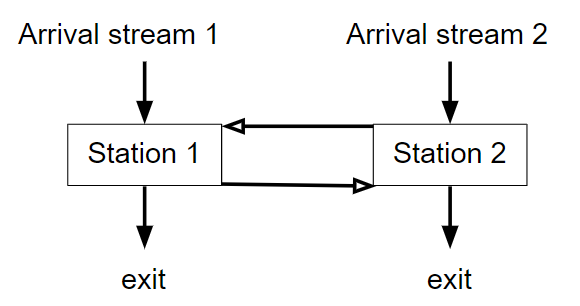

In [4]:
Image('../Images/stability_example.png', width=820)

In [5]:
### your solution

<div dir="rtl"> 

## תרגיל 2
    
###  בתרגיל הבא נרצה לראות כיצד שונות זמן השירות משפיעה על זמני המתנה.
    
### הפונקציה create_Erlang_given_ph_size נותנת לנו ייצוג של משתנה מקרי PH בהינתן הגודל שמזינים לו. תוחלת של Erlang היא 1
    
### לדוגמא: 

In [6]:
a, S = create_Erlang_given_ph_size(3)

a, S


(array([1., 0., 0.]),
 array([[-3.,  3.,  0.],
        [ 0., -3.,  3.],
        [ 0.,  0., -3.]]))

<div dir="rtl">  

### אם נחשב את הSCV, נקבל:

In [7]:
moms_erlang = compute_first_n_moments(a,S, 2)

var_erlang = moms_erlang[1]-moms_erlang[0]**2

SCV_erlang = var_erlang/moms_erlang[0]**2


SCV_erlang

np.float64(0.33333333333333326)

<div dir="rtl"> 

### נא חשבו את זמן השהייה הממוצע של תור יחיד כאשר התפלגות הגעה היא מעריכית עם קצב  0.7 והתפלגות השירות היא Erlang עם תוחלת 1 בגדלים שונים. Erlang הוא כאמור סכום של מעריכים, אז הגודל במקרה הזה הוא כמות המעריכיים שנסכום. 
    
### יש לחשב עבור גודל 1, 10 ו-50.
    
### ניתן לעשות סימולציה עם ה Queue_single_station class
    
### Queue_single_station מקבלת 3 ארגיומנטים: קצב הגעה,זמני שירות מוגרלים וזמן סימולציה

<div dir="rtl"> 

### שאלה: נא הסבר.י את התוצאה שהתקבלה

In [13]:

# computing average waiting time with PH size: ph_size
ph_size = 50
a, S = create_Erlang_given_ph_size(ph_size)
moms_erlang = compute_first_n_moments(a,S, 2)

var_erlang = moms_erlang[1]-moms_erlang[0]**2

SCV_erlang = var_erlang/moms_erlang[0]**2

services = SamplesFromPH(ml.matrix(a), S, 15000)

In [14]:

lamda = 0.7
sim_time = 10000
queue_single_station = Queue_single_station(lamda, services, sim_time)
queue_single_station.run()

print(ph_size, SCV_erlang, np.array(queue_single_station.waiting_times).mean())

50 0.019999999999999796 2.2039194194298086


<div dir="rtl"> 


## תרגיל 3

In [17]:
a, S ,moms, services = pkl.load(open('../pkls/assignemt2_ex_3_data.pkl','rb'))

<div dir="rtl"> 


### קיבלתי נתוני עבר של זמני שירות תחת המשתנה services. 
    
### 1. יש למצוא התפלגות  PH מתאימה. ניתן לנסות בכמה גדלים עד שמגיעים להתפלגות מתאימה. יש להוציא plot של הסטורגמה של הנתונים מול ההתפלגות האמיתית.
    
#### את ההתפלגות האמיתית ניתן להדפיס ע"י שורת הקוד הבאה:

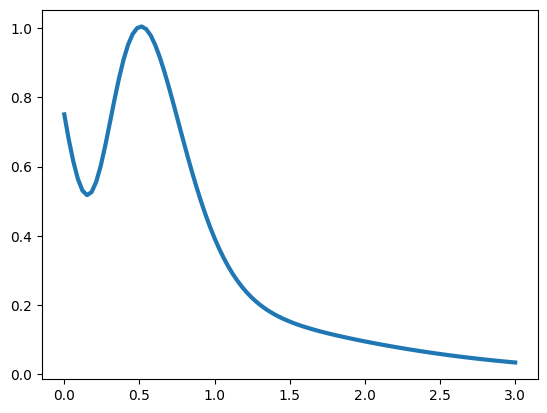

In [19]:
x_vals  = np.linspace(0,3,100)
y_vals = compute_pdf_within_range(x_vals, a, S)

plt.figure()
# plt.hist(PH_samples, density = True, bins = 500)
plt.plot(x_vals, y_vals, lw = 3)
plt.show()

<div dir="rtl"> 

### נניח שלתור מגיעים מתהליך פואסון בקצב 0.75. ננסה לחשב מה השגיאה של התפלגות מספר הצרכנים במערכת כאשר משערכים את ההתפלגות זמני שירות. יש לחשב את השגיאה עבור PH בגדול 2 עד 10. 
    
### לבסוף יש להוציא דרך המתא
    
### את הערך האמיתי יש לחשב לפי הקוד שלמטה: 

In [25]:
sim_time = 500000
lamda = 0.75
queue_single_station_true = Queue_single_station(lamda, services, sim_time)
queue_single_station_true.run()
steady_true = queue_single_station_true.get_steady_single_station()

<div dir="rtl"> 

### למטה יש לחשב עבור כל התאמה PH את ההתפלגות של מספר הצרכנים במערכת כפונקציה של גדול הPH. שגיאה מחושבת לפי SAE. 

Runtime for 8 is 13.506628036499023


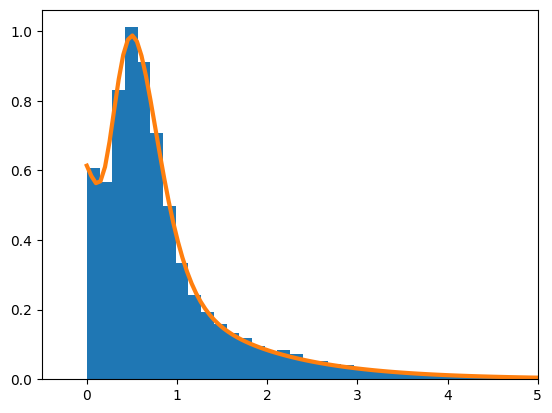

In [21]:
# Example fit for size 8

size = 8
begin = time.time()
res_EM = PHFromTrace(services, size)
x_vals  = np.linspace(0,5,100)
a_EM = np.array(res_EM[0]).flatten()
S_EM = np.array(res_EM[1])
end = time.time()
print('Runtime for {} is {}' .format(size, end-begin))

y_vals = compute_pdf_within_range(x_vals, a_EM, S_EM)

plt.figure()
plt.hist(services, density = True, bins = 800)
plt.plot(x_vals, y_vals, lw = 3)
plt.xlim(-0.5,5)
plt.show()

In [23]:
services_8 = SamplesFromPH(res_EM[0], res_EM[1], 50000)

sim_time = 500000
lamda = 0.75
queue_single_station_true = Queue_single_station(lamda, services, sim_time)
queue_single_station_true.run()
steady_size_8 = queue_single_station_true.get_steady_single_station()

In [ ]:
SAE_size_8 = np.abs(steady_true-steady_size_8).sum()
SAE_size_8